In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
import numpy as np

In [2]:
df = pd.read_csv(r"E:\PORTFOLIO_PROJECTS\PYTHON-PROJECTS\02-Cafe-Sales\DATA\cleaned\cafe_sales_clean.csv")
df.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_4565754,smoothie,NaN,4.0,NaN,digital wallet,takeaway,2023-10-06
1,TXN_2962976,juice,NaN,3.0,NaN,NaN,NaN,2023-03-17
2,TXN_4628338,coffee,NaN,2.0,NaN,cash,NaN,2023-12-25
3,TXN_2023651,sandwich,NaN,4.0,NaN,cash,in-store,2023-05-25
4,TXN_3174336,cookie,NaN,1.0,1.0,NaN,NaN,2023-07-17


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    10000 non-null  str    
 1   item              9667 non-null   str    
 2   quantity          9521 non-null   float64
 3   price_per_unit    9467 non-null   float64
 4   total_spent       9960 non-null   float64
 5   payment_method    7421 non-null   str    
 6   location          6735 non-null   str    
 7   transaction_date  9540 non-null   str    
dtypes: float64(3), str(5)
memory usage: 1003.3 KB


In [4]:
df.isnull().sum()

transaction_id         0
item                 333
quantity             479
price_per_unit       533
total_spent           40
payment_method      2579
location            3265
transaction_date     460
dtype: int64

In [5]:
df.duplicated().sum().any()

np.False_

1. Overall Business Health

In [6]:
df_clean = df.replace(['ERROR', 'error', 'unknown'], np.nan, inplace=True)

print("********** Basic Statistics ***************")

# Total Revenue
print(f"Total Revenue: ${df_clean['total_spent'].sum():.2f}")

# Total Transaction
print(f"Total Transaction: {df['transaction_id'].nunique()}")

# Average Order Value
print(f"Average Order value: ${df_clean['total_spent'].mean():.2f}")

df_clean.describe()


********** Basic Statistics ***************
Total Revenue: $88952.00
Total Transaction: 10000
Average Order value: $8.93


,quantity,price_per_unit,total_spent
count,9521.000000,9467.000000,9960.000000
mean,3.028463,2.949984,8.930924
std,1.419007,1.278450,6.004475
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,25.000000


2. Product Performance

In [8]:
top_3_items_BR = df_clean.groupby('item')['total_spent'].sum().sort_values(ascending=False)
top_3_formatted = top_3_items_BR.apply(lambda val: f"${int(val)}")
top_3_formatted.head(3)

item
salad       $17320
sandwich    $13664
smoothie    $13320
Name: total_spent, dtype: str

3. Time & Seasonality

In [ ]:
# Monthly-Wise Analyzing
df_clean['monthly_sales'] = df_clean['transaction_date'].dt.month_name()

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_revenue = df_clean.groupby("monthly_sales")['total_spent'].sum().reindex(month_order)

monthly_revenue.apply(lambda val: f"${int(val)}")

monthly_sales
January      $7242
February     $6633
March        $7214
April        $7168
May          $6941
June         $7350
July         $6877
August       $7077
September    $6846
October      $7302
November     $6957
December     $7177
Name: total_spent, dtype: str

In [12]:
df_clean['transaction_date'] = pd.to_datetime(df['transaction_date'], format='%Y-%m-%d')
df_clean['day_of_week'] = df_clean['transaction_date'].dt.day_name()
day_order = ['Monday', 'Tuesday','Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_revenue = df_clean.groupby('day_of_week')['total_spent'].sum().reindex(day_order)
daily_revenue.apply(lambda val: f"${int(val)}")

day_of_week
Monday       $12135
Tuesday      $12030
Wednesday    $11616
Thursday     $12394
Friday       $12317
Saturday     $12007
Sunday       $12285
Name: total_spent, dtype: str

5. Location Performance

In [21]:
revenue_by_location = df_clean.groupby("location")["total_spent"].sum().sort_values(ascending=False)
revenue_by_location.apply(lambda val: f"${int(val)}")

location
in-store    $27127
takeaway    $26487
Name: total_spent, dtype: str

Visualization

Text(0.5, 0, 'Total Revenue ($)')

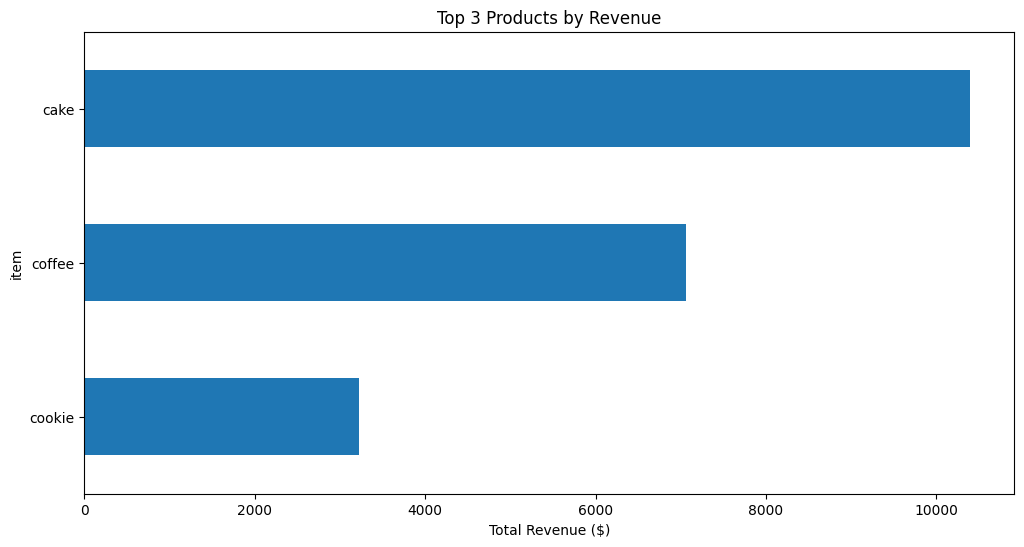

In [34]:
df_clean.groupby('item')['total_spent'].sum().head(3).sort_values(ascending=True).plot(kind='barh', figsize=(12,6))
plt.title("Top 3 Products by Revenue")
plt.xlabel("Total Revenue ($)")


In [ ]:
df_clean.columns

Index(['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent',
       'payment_method', 'location', 'transaction_date', 'day_of_week',
       'monthly_sales'],
      dtype='str')